In [1]:
#import the libraries
import pandas as pd
import numpy as np

In [2]:
#read the dataset and check the first five rows
LC = pd.read_csv("loan.csv")
LC.head()

C:\Users\ramch\Software\lib\site-packages\IPython\core\interactiveshell.py:3063: DtypeWarning: Columns (47) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
0,1077501,1296599,5000,5000,4975.0,36 months,10.65%,162.87,B,B2,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
1,1077430,1314167,2500,2500,2500.0,60 months,15.27%,59.83,C,C4,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
2,1077175,1313524,2400,2400,2400.0,36 months,15.96%,84.33,C,C5,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
3,1076863,1277178,10000,10000,10000.0,36 months,13.49%,339.31,C,C1,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
4,1075358,1311748,3000,3000,3000.0,60 months,12.69%,67.79,B,B5,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN


In [4]:
lst_columns = LC.columns
lst_columns = list(lst_columns)

In [5]:
# TO remove any fully null columns
for i in lst_columns:
    if LC[i].isnull().sum() == 39717:
        LC = LC.drop(i,axis=1)

In [6]:
# If the column has same  value, we can drop it as it doesnt give any much information

n_lst = list(LC.columns)
def is_unique(s):
    a = s.to_numpy() 
    return (a[0] == a).all()

for i in n_lst:
    if(is_unique(LC[i])):
        LC=LC.drop(i,axis=1)

In [7]:
LC.shape

(39717, 51)

In [8]:
LC.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'url', 'desc', 'purpose', 'title', 'zip_code',
       'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
       'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record',
       'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
       'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'chargeoff_within_12_mths', 'pub_rec_bankruptcies', 'tax_liens'],
      dtype='object')

### Consumer Attributes: 
        id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'url', 'desc', 'purpose', 'title', 'zip_code',
       'addr_state'

#### Loan Attributes: 
        'dti', 'delinq_2yrs', 'earliest_cr_line',
       'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record',
       'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
       'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'chargeoff_within_12_mths', 'pub_rec_bankruptcies', 'tax_liens'

revol_util: If a person has 2 credit carad with limit of 1 lac each and he has used 20k from his credit, then revol_bal=2L-20k
and revol_util = 20k/2L. So, lower the revol_util, better =. Higher the revol_bal, better.

In [9]:
LC = LC.drop("zip_code",axis=1)

In [10]:
LC = LC.drop("desc",axis=1)

In [11]:
LC = LC.drop("url",axis=1)

In [12]:
#import the necessary libraries
import warnings
warnings.filterwarnings("ignore")
import seaborn as sns

#import the plotting libraries
import matplotlib.pyplot as plt
%matplotlib inline

In [19]:
LC["loan_amnt"]

0         5000
1         2500
2         2400
3        10000
4         3000
         ...  
39712     2500
39713     8500
39714     5000
39715     5000
39716     7500
Name: loan_amnt, Length: 39717, dtype: int64

In [24]:
tb1 = pd.pivot_table(data=LC,index="loan_status", columns="grade",values="loan_amnt")

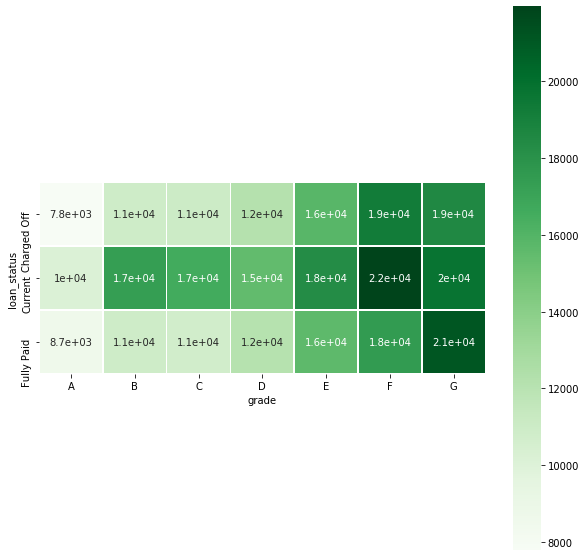

In [25]:
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(tb1,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

#### More loan is  taken by people with lower grade in all three loan_status ####

In [28]:
LC["interest"] = LC["int_rate"].apply(lambda x:x.replace("%",""))

In [29]:
LC["interest"] = LC["interest"].astype("float64")

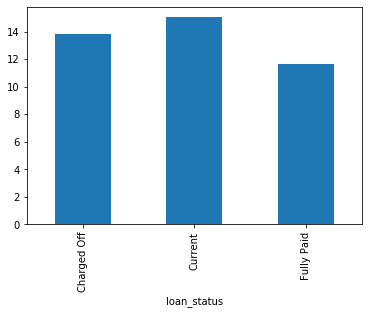

In [31]:
LC.groupby(['loan_status'])['interest'].mean().plot.bar()

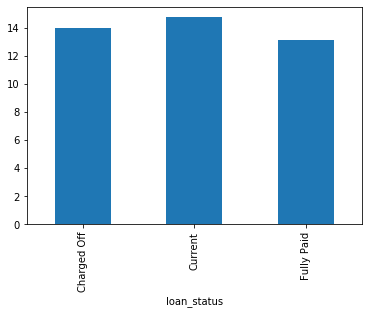

In [34]:
LC.groupby(['loan_status'])['dti'].mean().plot.bar()

dti much doesnt speak as they almost have close values!!!

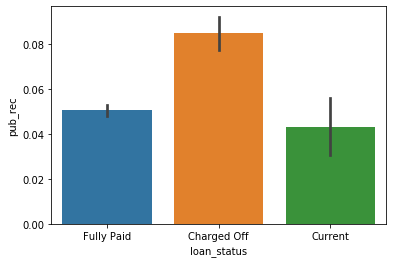

In [37]:
sns.barplot(data=LC, x="loan_status", y="pub_rec")
plt.show()

###### VERY VERY IMPORTANT #####

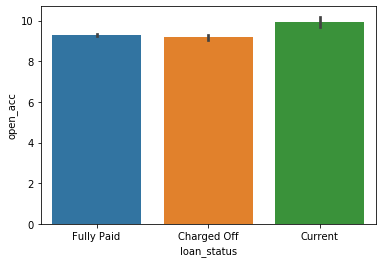

In [38]:
sns.barplot(data=LC, x="loan_status", y="open_acc")
plt.show()

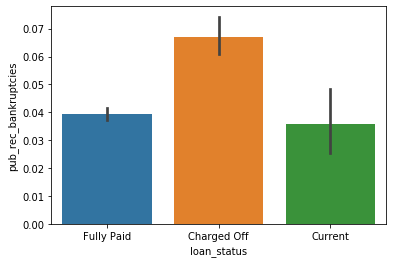

In [39]:

sns.barplot(data=LC, x="loan_status", y="pub_rec_bankruptcies")
plt.show()

#### VERY IMPORTANT ####

In [42]:
#sns.barplot(data=LC, x="loan_status", y="purpose")
#plt.show()
LC["delinq_2yrs"].isnull().sum()

0

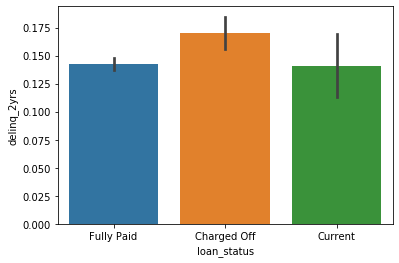

In [44]:
sns.barplot(data=LC, x="loan_status", y="delinq_2yrs")
plt.show()

#### IMPORTANT ###

In [46]:
LC["inq_last_6mths"].isnull().sum()

0

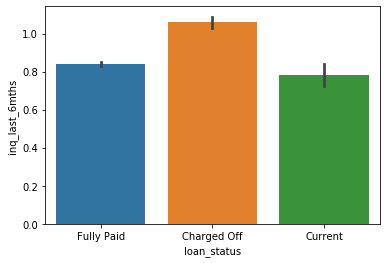

In [47]:
sns.barplot(data=LC, x="loan_status", y="inq_last_6mths")
plt.show()

### Again important attribute ###

In [48]:
LC.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'purpose', 'title', 'addr_state', 'dti',
       'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths',
       'mths_since_last_delinq', 'mths_since_last_record', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'chargeoff_within_12_mths', 'pub_rec_bankruptcies', 'tax_liens',
       'interest'],
      dtype='object')

In [49]:
LC["mths_since_last_delinq"].isnull().sum()

25682

In [50]:
LC.shape

(39717, 49)

In [51]:
LC["revol_bal"]

0        13648
1         1687
2         2956
3         5598
4        27783
         ...  
39712     7274
39713     8847
39714     9698
39715    85607
39716     4175
Name: revol_bal, Length: 39717, dtype: int64

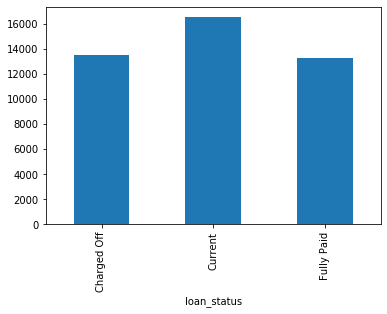

In [52]:
LC.groupby(['loan_status'])['revol_bal'].mean().plot.bar()

In [55]:
LC["revol_util"] = LC["revol_util"].astype("str")
LC["revol_util"] = LC["revol_util"].apply(lambda x:x.replace("%",""))

In [58]:
LC["revol_util"] = LC["revol_util"].astype("float64")

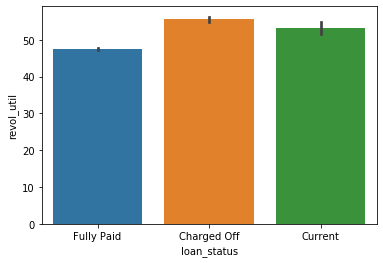

In [59]:
sns.barplot(data=LC, x="loan_status", y="revol_util")
plt.show()

### Kind of Important ###

In [61]:
LC["chargeoff_within_12_mths"].value_counts()

0.0    39661
Name: chargeoff_within_12_mths, dtype: int64

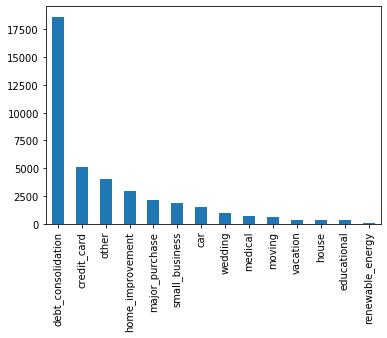

In [62]:
#Question - Plot a bar plot for checking the 4th highest Android version type
LC['purpose'].value_counts().plot.bar()
plt.show()

In [66]:
LC["emp_length"] = LC["emp_length"].astype("str")
LC["emplength"] = LC["emp_length"].apply(lambda x:x.rstrip("years"))

In [68]:
LC["emplength"] = LC["emplength"].apply(lambda x:x.replace("+",""))

In [69]:
LC["emplength"]

0         10 
1        < 1 
2         10 
3         10 
4          1 
         ... 
39712      4 
39713      3 
39714    < 1 
39715    < 1 
39716    < 1 
Name: emplength, Length: 39717, dtype: object

In [70]:
LC["emplength"] = LC["emplength"].apply(lambda x:x.replace("< 1","1"))

In [76]:
emp = LC[LC["emplength"] != "nan"]

In [77]:
emp.shape

(38642, 50)

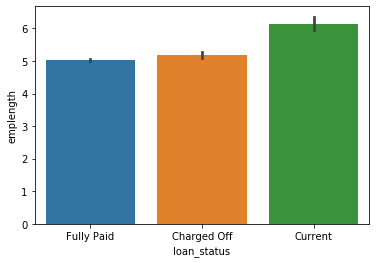

In [79]:
emp["emplength"] = emp["emplength"].astype("float64")
sns.barplot(data=emp, x="loan_status", y="emplength")
plt.show()

In [82]:
emp["emplength"] = emp["emplength"].astype("int32")

In [83]:
emp["emplength"]

0        10
1         1
2        10
3        10
4         1
         ..
39712     4
39713     3
39714     1
39715     1
39716     1
Name: emplength, Length: 38642, dtype: int32

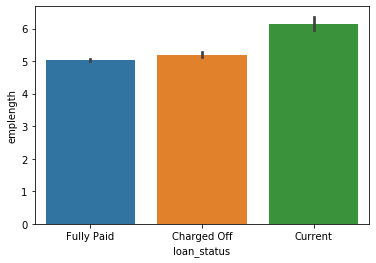

In [84]:
sns.barplot(data=emp, x="loan_status", y="emplength")
plt.show()

Not much difference between fully paid and Charged off

In [87]:
LC["term"] = LC["term"].apply(lambda x:x.rstrip("months"))

In [89]:
LC["term"] = LC["term"].astype("int32")

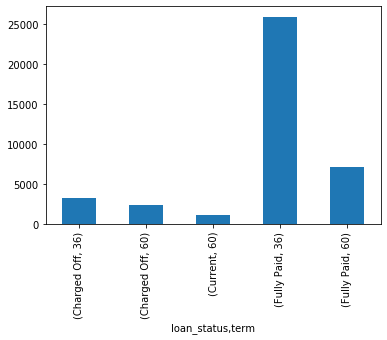

In [91]:
LC.groupby(['loan_status'])['term'].value_counts().plot.bar()

In [92]:
LC.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'purpose', 'title', 'addr_state', 'dti',
       'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths',
       'mths_since_last_delinq', 'mths_since_last_record', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'chargeoff_within_12_mths', 'pub_rec_bankruptcies', 'tax_liens',
       'interest', 'emplength'],
      dtype='object')

In [95]:
LC["annual_inc"].dtype

dtype('float64')

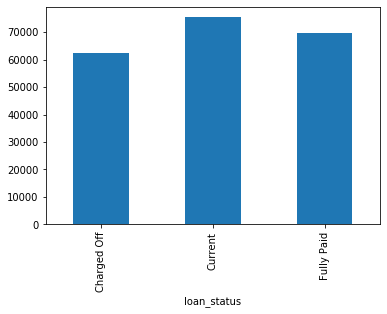

In [98]:
LC.groupby(['loan_status'])['annual_inc'].mean().plot.bar()

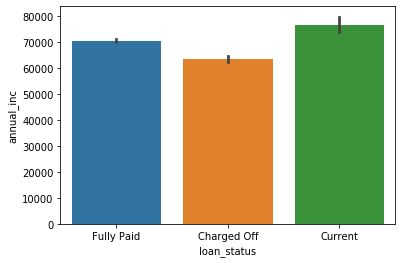

In [99]:
sns.barplot(data=emp, x="loan_status", y="annual_inc")
plt.show()

In [100]:
# Loss calculated on the basis of principle amount 
LC["Loss"] = LC["funded_amnt"] - LC["total_rec_prncp"]

In [104]:
nloss= LC[LC["Loss"] < 0]

In [106]:
nloss["loan_status"]

1786     Fully Paid
2778     Fully Paid
3166     Fully Paid
3471     Fully Paid
3783     Fully Paid
            ...    
32089    Fully Paid
32130    Fully Paid
33851    Fully Paid
34078    Fully Paid
34748    Fully Paid
Name: loan_status, Length: 116, dtype: object

In [ ]:
#tb21= pd.pivot_table(data=LC,index="loan_status", columns="grade",values="loan")

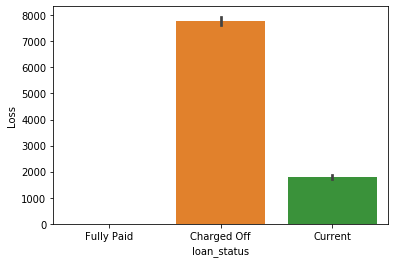

In [108]:
sns.barplot(data=LC, x="loan_status", y="Loss")
plt.show()